In [9]:
import json
from concurrent.futures import ThreadPoolExecutor
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import trimesh
from PIL import Image
from scipy import ndimage, stats

DATA = Path("/mnt/c/tinhanh/project/ai_challenge/data/fve")   # Windows: Path(r"C:\tinhanh\project\ai_challenge\data\fve")
pd.set_option("display.width", 200)

In [2]:
data_path = "/mnt/c/tinhanh/project/ai_challenge/data/fve"

data_dir = Path(data_path)


train_dir = data_dir / "train"
val_dir = data_dir / "val"

In [13]:
def as_files(entry) -> dict[str, Path]:
    """Normalise one trainkey2files value (list, dict or folder) into {filename: Path}."""
    if isinstance(entry, (str, Path)) and (DATA / entry).is_dir():
        return {p.name: p for p in (DATA / entry).iterdir()}
    paths = entry.values() if isinstance(entry, dict) else entry
    out = {}
    for p in paths:
        p = Path(p)
        out[p.name] = p if p.is_absolute() else DATA / p
    return out

def foreground_mask(rgb: np.ndarray, thr: float = 18.0) -> np.ndarray:
    """Object mask: pixels that differ from the per-row backdrop colour (left/right borders)."""
    img = rgb.astype(np.float32)
    border = np.concatenate([img[:, :24], img[:, -24:]], axis=1)
    bg_row = np.median(border, axis=1, keepdims=True)          # (H, 1, 3) backdrop colour per row
    mask = np.abs(img - bg_row).max(axis=2) > thr
    mask = ndimage.binary_opening(mask, iterations=2)
    lab, n = ndimage.label(mask)
    if n == 0:
        return mask
    sizes = ndimage.sum(mask, lab, range(1, n + 1))
    return ndimage.binary_fill_holes(lab == (np.argmax(sizes) + 1))

In [3]:
trainkey2files = {}
valkey2files = {}


for path in train_dir.rglob("*"):
    if not path.is_file() or path.suffix.lower() not in {".json", ".ply", ".png"}:
        continue
    key = str(path.parent.relative_to(train_dir.parent))
    if key not in trainkey2files:
        trainkey2files[key] = {}
    
    trainkey2files[key][path.suffix.lower().lstrip(".")] = str(path)


for path in val_dir.rglob("*"):
    if not path.is_file() or path.suffix.lower() not in {".json", ".ply", ".png"}:
        continue
    key = str(path.parent.relative_to(val_dir.parent))
    if key not in valkey2files:
        valkey2files[key] = {}
    
    valkey2files[key][path.suffix.lower().lstrip(".")] = str(path)

In [6]:
example = trainkey2files['train/bakery/bagel/mf3d_bagel_001']

In [11]:
key = "train/bakery/bagel/mf3d_bagel_001"
files = as_files(trainkey2files[key])
print({k: str(v) for k, v in files.items()})

gt = json.loads(files["gt.json"].read_text())
print(json.dumps(gt, indent=2))
vol = gt["volume"]["primary_cm3"]
bx, by, bz = gt["bbox_mm"]
bbox_cm3 = bx * by * bz / 1000
print(f"\nvolume={vol:.2f} cm³  bbox={bbox_cm3:.1f} cm³  fill={vol / bbox_cm3:.3f}  "
      f"density={(gt['weight_g'] / vol) if gt.get('weight_g') else None}")

{'gt.json': '/mnt/c/tinhanh/project/ai_challenge/data/fve/train/bakery/bagel/mf3d_bagel_001/gt.json', 'mesh.ply': '/mnt/c/tinhanh/project/ai_challenge/data/fve/train/bakery/bagel/mf3d_bagel_001/mesh.ply', 'rgb_industrial.png': '/mnt/c/tinhanh/project/ai_challenge/data/fve/train/bakery/bagel/mf3d_bagel_001/rgb_industrial.png'}
{
  "sample_id": "mf3d_bagel_001",
  "timepoint": "T0",
  "category": "bagel",
  "category_l1": "bakery",
  "group": "bakery",
  "source": "metafood3d",
  "volume": {
    "primary_cm3": 283.09,
    "gt_protocol": "mesh_primary",
    "gt_confidence": "high",
    "disp_direct_cm3": null,
    "disp_sealed_cm3": null,
    "mesh_cm3": 283.09,
    "xlsx_volume_cm3": 283.09,
    "volume_rel_err_vs_xlsx": 5.62776378476605e-06
  },
  "weight_g": 102.0,
  "freshness": {
    "grade": null
  },
  "bbox_mm": [
    114.2,
    106.8,
    43.2
  ],
  "mesh": {
    "n_faces": 150000,
    "n_vertices": 74996,
    "n_faces_source": 552582,
    "decimated": true,
    "volume_cm3_afte

image: (1024, 1024) RGB metadata: {}
object area=0.267 of frame  bbox_w=0.663  bbox_h=0.525  centroid=(514,550)  horizon_row=38


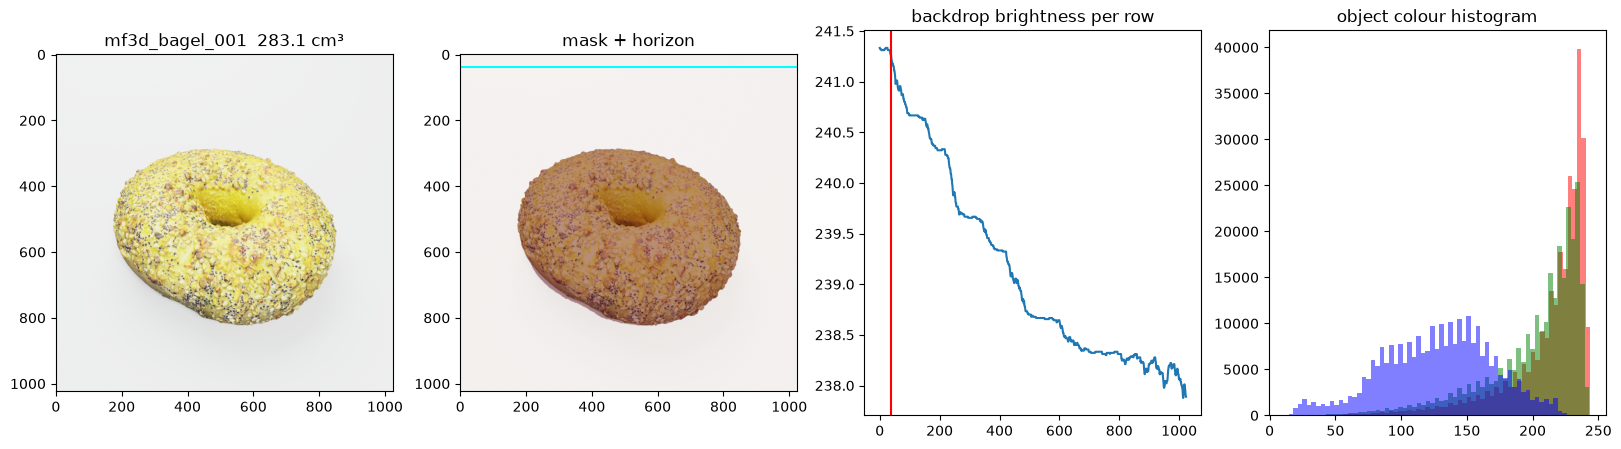

In [14]:
im = Image.open(files["rgb_industrial.png"])
print("image:", im.size, im.mode, "metadata:", im.info)
rgb = np.asarray(im.convert("RGB"))
mask = foreground_mask(rgb)
ys, xs = np.nonzero(mask)
gray = rgb.mean(axis=2)
profile = ndimage.uniform_filter1d(np.median(gray[:, :24], axis=1), 15)   # backdrop brightness per row
horizon = int(np.argmax(np.abs(np.diff(profile))))
print(f"object area={mask.mean():.3f} of frame  bbox_w={np.ptp(xs) / rgb.shape[1]:.3f}  "
      f"bbox_h={np.ptp(ys) / rgb.shape[0]:.3f}  centroid=({xs.mean():.0f},{ys.mean():.0f})  horizon_row={horizon}")

fig, ax = plt.subplots(1, 4, figsize=(20, 5))
ax[0].imshow(rgb); ax[0].set_title(f"{gt['sample_id']}  {vol:.1f} cm³")
ax[1].imshow(rgb); ax[1].imshow(mask, alpha=0.4, cmap="Reds"); ax[1].axhline(horizon, c="cyan"); ax[1].set_title("mask + horizon")
ax[2].plot(profile); ax[2].axvline(horizon, c="r"); ax[2].set_title("backdrop brightness per row")
for c, col in enumerate("rgb"):
    ax[3].hist(rgb[..., c][mask].ravel(), bins=64, color=col, alpha=0.5)
ax[3].set_title("object colour histogram")
plt.show()

verts=74996 faces=150000 watertight=False winding_ok=True
mesh volume=283.09 cm³ vs label 283.09  (rel diff 1.16e-05)
AABB extents mm: [114.2 106.8  43.2]  vs bbox_mm [114.2, 106.8, 43.2]
OBB extents mm: [117.2  99.9  41.9]  fill_obb=0.577  hull_ratio=0.876  sphericity=0.722


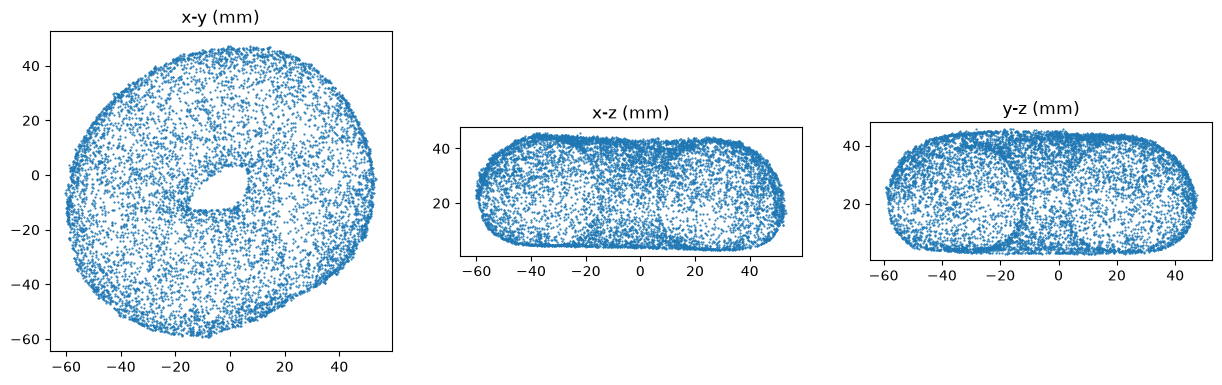

In [15]:
mesh = trimesh.load(files["mesh.ply"], process=False)
v_mm3 = abs(mesh.volume)
print(f"verts={len(mesh.vertices)} faces={len(mesh.faces)} watertight={mesh.is_watertight} winding_ok={mesh.is_winding_consistent}")
print(f"mesh volume={v_mm3 / 1000:.2f} cm³ vs label {vol:.2f}  (rel diff {abs(v_mm3 / 1000 - vol) / vol:.2e})")
print("AABB extents mm:", mesh.extents.round(1), " vs bbox_mm", gt["bbox_mm"])
obb = mesh.bounding_box_oriented.primitive.extents
print("OBB extents mm:", np.sort(obb)[::-1].round(1),
      f" fill_obb={v_mm3 / np.prod(obb):.3f}  hull_ratio={v_mm3 / mesh.convex_hull.volume:.3f}  "
      f"sphericity={np.pi ** (1 / 3) * (6 * v_mm3) ** (2 / 3) / mesh.area:.3f}")

pts = mesh.vertices[np.random.default_rng(0).choice(len(mesh.vertices), min(8000, len(mesh.vertices)), replace=False)]
fig, ax = plt.subplots(1, 3, figsize=(15, 5))
for a, (i, j, name) in zip(ax, [(0, 1, "x-y"), (0, 2, "x-z"), (1, 2, "y-z")]):
    a.scatter(pts[:, i], pts[:, j], s=0.3); a.set_aspect("equal"); a.set_title(f"{name} (mm)")
plt.show()

In [17]:
ALL_LARGE = {"hazelnut", "longan", "loquat"}   # whole category in the oversized mode

def build_index(root: Path = DATA) -> pd.DataFrame:
    rows = []
    for split in ("train", "val"):
        for img in sorted((root / split).rglob("rgb_industrial.png")):
            d = img.parent
            group, cat, sid = d.relative_to(root / split).parts
            row = dict(key=f"{split}/{group}/{cat}/{sid}", split=split, group=group, category=cat,
                       sample_id=sid, source=sid.split("_")[0], img=str(img))
            if (d / "gt.json").exists():
                g = json.loads((d / "gt.json").read_text())
                row.update(volume=g["volume"]["primary_cm3"], l1=g["category_l1"], weight_g=g["weight_g"],
                           conf=g["volume"]["gt_confidence"], bx=g["bbox_mm"][0], by=g["bbox_mm"][1], bz=g["bbox_mm"][2])
            rows.append(row)
    df = pd.DataFrame(rows)
    df["ln_vol"] = np.log(df["volume"])
    df["dim_max"] = df[["bx", "by", "bz"]].max(axis=1)
    df["fill"] = df["volume"] / (df["bx"] * df["by"] * df["bz"] / 1000)
    df["density"] = df["weight_g"] / df["volume"]
    return df


def flag_large_mode(df: pd.DataFrame, gap_ratio: float = 30.0) -> pd.Series:
    """Split each category at its largest volume gap if the gap is >= gap_ratio."""
    flag = pd.Series(False, index=df.index)
    for cat, g in df[df["volume"].notna()].groupby("category"):
        if cat in ALL_LARGE:
            flag[g.index] = True
            continue
        ln = np.sort(g["ln_vol"].to_numpy())
        if len(ln) > 1 and np.diff(ln).max() >= np.log(gap_ratio):
            cut = ln[np.argmax(np.diff(ln)) + 1]
            flag[g.index[g["ln_vol"] >= cut]] = True
    return flag


df = build_index()
df["large"] = flag_large_mode(df)
tr, va = df[df.split == "train"], df[df.split == "val"]
print(pd.crosstab(df.split, df.source, margins=True))

source  mf3d  omni   All
split                   
train    408  1634  2042
val      102   409   511
All      510  2043  2553


count     2042.00
mean      1286.91
std       3584.81
min          0.38
1%           3.78
5%          11.46
25%         47.08
50%        116.87
75%        295.15
95%      10757.06
99%      17240.66
max      33272.68
Name: volume, dtype: float64


TypeError: Axes.boxplot() got an unexpected keyword argument 'labels'

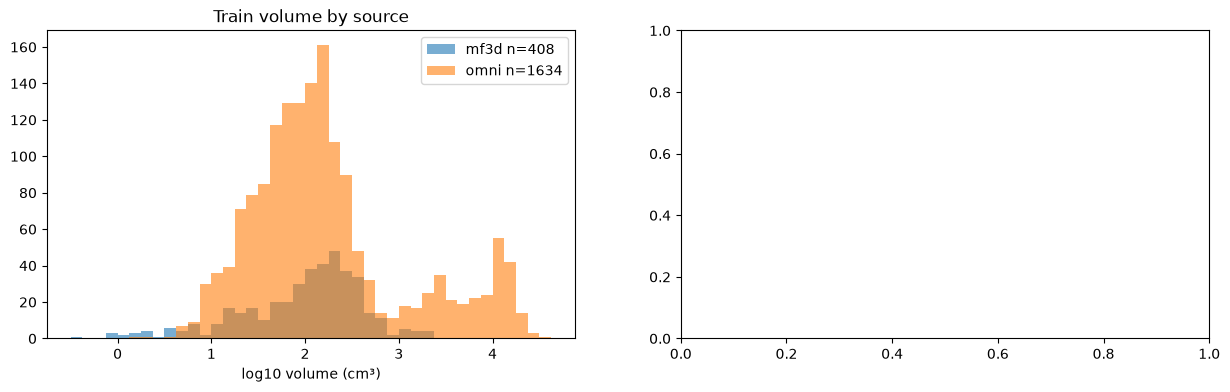

In [18]:
# %% B2. Train label distribution
print(tr["volume"].describe(percentiles=[.01, .05, .25, .5, .75, .95, .99]).round(2))
fig, ax = plt.subplots(1, 2, figsize=(15, 4))
for src, g in tr.groupby("source"):
    ax[0].hist(np.log10(g["volume"]), bins=np.arange(-0.5, 4.75, 0.125), alpha=0.6, label=f"{src} n={len(g)}")
ax[0].set(xlabel="log10 volume (cm³)", title="Train volume by source"); ax[0].legend()
order = tr.groupby("l1")["ln_vol"].median().sort_values().index
ax[1].boxplot([np.log10(tr.loc[tr.l1 == c, "volume"]) for c in order], labels=order)
ax[1].set(ylabel="log10 volume", title="By coarse category"); plt.setp(ax[1].get_xticklabels(), rotation=30, ha="right")
plt.show()

In [19]:
base = tr[~tr.large]
cat = tr.groupby("category").agg(n=("volume", "size"), l1=("l1", "first"), median=("volume", "median"),
                                 n_large=("large", "sum")).assign(
    large_rate=lambda d: d.n_large / d.n,
    ln_std_base=base.groupby("category")["ln_vol"].std(),
    base_median=base.groupby("category")["volume"].median(),
    large_median=tr[tr.large].groupby("category")["volume"].median())
print("objects/category:", cat.n.describe().round(1).to_dict(), " <=3 objects:", (cat.n <= 3).sum())
print("within-category ln-std (base mode): median", round(cat.ln_std_base.median(), 3))
print(f"\nlarge mode: {tr.large.sum()} objects ({tr.large.mean():.1%})")
print(cat[cat.n_large > 0].sort_values("large_rate", ascending=False)
      [["n", "n_large", "large_rate", "base_median", "large_median"]].round(1))

objects/category: {'count': 164.0, 'mean': 12.5, 'std': 10.5, 'min': 1.0, '25%': 3.0, '50%': 8.0, '75%': 21.0, 'max': 65.0}  <=3 objects: 48
within-category ln-std (base mode): median 0.521

large mode: 188 objects (9.2%)
                  n  n_large  large_rate  base_median  large_median
category                                                           
longan           15       15         1.0          NaN        9555.0
hazelnut         14       14         1.0          NaN        4417.6
loquat           15       15         1.0          NaN       10799.6
haw_thorn        30       28         0.9         13.1       13596.1
cherry           11       10         0.9          8.2        7774.2
brussels_sprout  15       13         0.9         14.5       12208.5
walnut           27       21         0.8         23.0       13253.0
beans             4        3         0.8          0.4         267.4
mac               4        3         0.8          1.5         215.6
green_beans       4        3  

In [20]:
# %% B4. sMAPE baselines (in-sample) + floor
def smape(y, p):
    y, p = np.asarray(y, float), np.asarray(p, float)
    return 100 * np.mean(2 * np.abs(p - y) / (np.abs(y) + np.abs(p)))

y = tr["volume"].to_numpy()
print("global median     :", round(smape(y, np.full_like(y, np.median(y))), 1))
print("category median   :", round(smape(y, tr.groupby("category")["volume"].transform("median")), 1))
mode_pred = np.where(tr["category"].map(cat.large_rate) > 0.5,
                     tr["category"].map(cat.large_median), tr["category"].map(cat.base_median))
print("mode-aware median :", round(smape(y, mode_pred), 1))
z = np.random.default_rng(0).standard_normal(100_000)
for s in (0.4, 0.52, 1.89):
    print(f"floor if ln-error std={s}: {100 * np.mean(2 * np.tanh(np.abs(s * z) / 2)):.1f}%")

global median     : 94.1
category median   : 46.5
mode-aware median : 45.9
floor if ln-error std=0.4: 31.1%
floor if ln-error std=0.52: 39.8%
floor if ln-error std=1.89: 107.8%


In [21]:
# %% B5. Shape + density
print("fill:", tr.fill.describe().round(3).to_dict())
print("within-category std ln(fill):", round(base.groupby("category")["fill"].apply(lambda s: np.log(s).std()).median(), 3))
print(tr[tr.density.notna()].groupby("l1")["density"].describe()[["count", "50%", "min", "max"]].round(2))

fill: {'count': 2042.0, 'mean': 0.431, 'std': 0.131, 'min': 0.001, '25%': 0.35, '50%': 0.447, '75%': 0.515, 'max': 0.883}
within-category std ln(fill): 0.166
                    count   50%   min    max
l1                                          
bakery               68.0  0.44  0.16   1.34
egg_nut              11.0  1.14  0.98   1.30
fruit                50.0  0.96  0.51   1.45
fruiting_vegetable   68.0  0.91  0.22  30.30
leafy_vegetable      11.0  0.74  0.18   1.33
meat_poultry_fish    55.0  0.90  0.41  20.40
prepared            142.0  0.75  0.13  13.18


In [22]:
comp = pd.concat({"train": tr.group.value_counts(normalize=True), "val": va.group.value_counts(normalize=True)}, axis=1)
print(comp.round(3))
print("val categories missing in train:", sorted(set(va.category) - set(tr.category)))
print("train categories missing in val:", len(set(tr.category) - set(va.category)))
print("val/train ratio per category, lowest:",
      (va.category.value_counts() / tr.category.value_counts()).dropna().sort_values().head(5).round(2).to_dict())


            train    val
group                   
fruits      0.247  0.213
vegetables  0.237  0.202
extra       0.197  0.192
bakery      0.191  0.270
packaged    0.053  0.041
seafood     0.038  0.037
meat        0.036  0.045
val categories missing in train: []
train categories missing in val: 3
val/train ratio per category, lowest: {'garlic': 0.05, 'coconut': 0.05, 'pastry': 0.05, 'oyster': 0.05, 'zongzi': 0.05}


In [24]:
def image_features(path: str, size: int = 256) -> dict:
    im = Image.open(path).convert("RGB").resize((size, size), Image.BILINEAR)
    rgb = np.asarray(im)
    m = foreground_mask(rgb)
    ys, xs = np.nonzero(m)
    gray = rgb.mean(axis=2)
    hsv = np.asarray(im.convert("HSV")).astype(float)
    prof = ndimage.uniform_filter1d(np.median(gray[:, :8], axis=1), 7)
    if xs.size == 0:
        return dict(area=0.0)
    return dict(area=m.mean(), bbox_w=np.ptp(xs) / size, bbox_h=np.ptp(ys) / size,
                aspect=(np.ptp(xs) + 1) / (np.ptp(ys) + 1), cx=xs.mean() / size, cy=ys.mean() / size,
                bottom=ys.max() / size, sat=hsv[..., 1][m].mean(), val=hsv[..., 2][m].mean(),
                r=rgb[..., 0][m].mean(), g=rgb[..., 1][m].mean(), b=rgb[..., 2][m].mean(),
                sharp=ndimage.laplace(gray)[m].var(), bg_top=gray[:8].mean(), bg_bottom=gray[-8:].mean(),
                horizon=np.argmax(np.abs(np.diff(prof))) / size)

with ThreadPoolExecutor(max_workers=8) as ex:
    feats = pd.DataFrame(list(ex.map(image_features, df["img"])), index=df.index)
df = df.join(feats)
FEATS = list(feats.columns)
tr, va = df[df.split == "train"], df[df.split == "val"]

ValueError: columns overlap but no suffix specified: Index(['area', 'bbox_w', 'bbox_h', 'aspect', 'cx', 'cy', 'bottom', 'sat', 'val', 'r', 'g', 'b', 'sharp', 'bg_top', 'bg_bottom', 'horizon'], dtype='str')